In [2]:
from scipy.special import hankel1
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
# параметры сетки и ячеек на стороне
n1 = 30
n2 = 30

# длина стороны
l1 = 1
l2 = 2

# центр сетки
c1 = 0
c2 = 0

# ширина шагов
h1 = l1/n1
h2 = l2/n2

k0=1

# сетка значений узлов разбиений на двумерном прямоугольнике
x1 = np.linspace(c1 - l1/2, c1 + l1/2, n1 + 1)
x2 = np.linspace(c2 - l2/2, c2 + l2/2, n2 + 1)

# сетка центров разбиений
x1_c = (x1[1:] + x1[:-1]) / 2
x2_c = (x2[1:] + x2[:-1]) / 2

# декартово произведение для единого массива центров

mesh = np.meshgrid(x1_c, x2_c)

In [46]:
h1, h2

(0.03333333333333333, 0.06666666666666667)

In [19]:
grid = np.array(mesh).reshape(2, -1).T

In [20]:
grid

array([[-0.48333333, -0.96666667],
       [-0.45      , -0.96666667],
       [-0.41666667, -0.96666667],
       ...,
       [ 0.41666667,  0.96666667],
       [ 0.45      ,  0.96666667],
       [ 0.48333333,  0.96666667]], shape=(900, 2))

In [30]:
def f_wave(x, d, k0=1, phi0=0):
    d = np.array(d)
    d_e = d / np.linalg.norm(d)
    x_d = np.dot(x, d_e)
    phase = k0 * x_d + phi0
    return np.exp(1j * phase)

In [31]:
f_grid = f_wave(grid, k0=20, phi0=1.5, d=[1, 1])

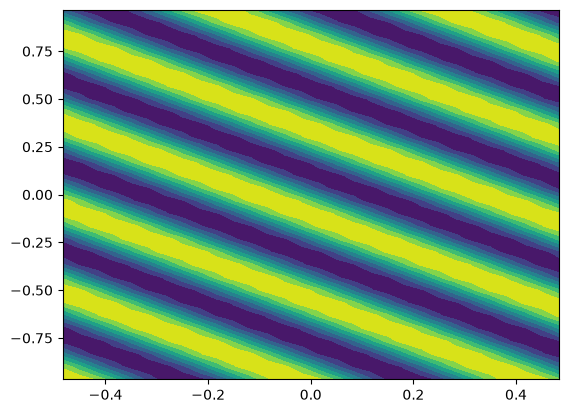

In [32]:
plt.contourf(grid[:, 0].reshape(n1, n2), grid[:, 1].reshape(n1, n2), f_grid.reshape(n1, n2).real)

In [57]:

# Функции рефракции
def refraction(x):
    
    mask = (np.abs(x[:, 0]) + np.abs(x[:, 1])) < 0.25

    return (1.5 + 0.08j) * mask

def ellipse_ref(
    x,
    eta=1.5 + 0.08j,
    center=(0.0, 0.25),
    focuses=(1.0, 1.5),
    radius=0.5
):
    # Полуоси эллипса
    a = radius * focuses[0]
    b = radius * focuses[1]

    # Уравнение эллипса: ((x-cx)/a)^2 + ((y-cy)/b)^2 < 1
    mask = (
        ((x[:, 0] - center[0]) / a) ** 2
        + ((x[:, 1] - center[1]) / b) ** 2
    ) < 1.0

    return eta * mask

In [ ]:
ref_grid = ellipsis_ref(grid, eta, (0, 0), (1.5, 1.5), 0.25)

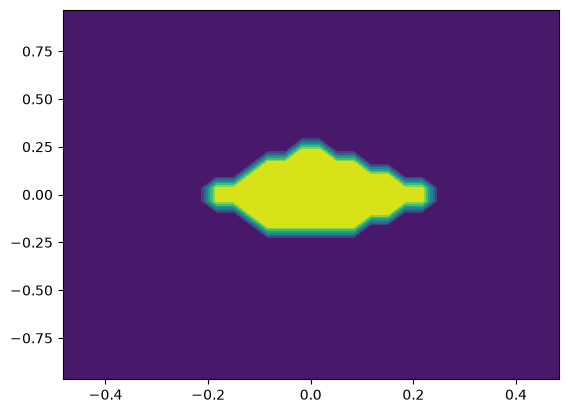

In [39]:
plt.contourf(
    grid[:, 0].reshape(n1, n2),
    grid[:, 1].reshape(n1, n2),
    refraction(grid).reshape(n1, n2).real
)

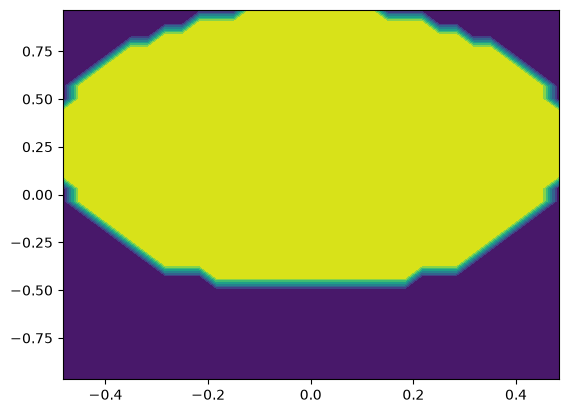

In [60]:
plt.contourf(
    grid[:, 0].reshape(n1, n2),
    grid[:, 1].reshape(n1, n2),
    ellipse_ref(grid).reshape(n1, n2).real
)

In [ ]:
# Green

def distances(x, y, h):
    """
    d(x, y) = ||x-y||^2
    d(x, x) = frac{h}{sqrt{pi}}
    """
    r_matrix = np.zeros((x.shape[0], x.shape[0]))
    r_matrix = np.linalg.norm(x[None, :, :] - y[:, None, :], ord=2, axis=2)
    r_matrix[np.arange(x.shape[0]), np.arange(y.shape[0])] = h / np.sqrt(np.pi)
    return r_matrix

def green(r_matrix, k0=1):
    g = 0.25j * hankel1(0, k0 * r)
    return 

In [54]:
r = distances(grid, grid, h=min(h1, h2))
g = green(r,)

In [55]:
g

In [ ]:
# матрица системы
A = (np.eye(grid.shape[0]) - k0**2 * ref_frid[None, :] * G * h1 * h2)

In [ ]:
u_grid = np.linalg.solve(A, f_grid)

In [ ]:
plt.imshow(u_grid.reshape(n1, n2).real)

In [ ]:
plt.contourf(
    grid[0].reshape(n1, n2], 
    grid[]grid.reshape(n1, n2).real)